# Oxford-IIIT Pet · ResNet-18 전이학습

**수강생용 코드 작성 및 흐름**

반려동물 사진 한 장을 37개 품종 중 하나로 분류합니다. ImageNet에서 학습된 ResNet-18로 사진의 특징을 추출하고, 새 분류기만 학습한 결과와 마지막 특징 블록까지 조정한 결과를 비교합니다. ResNet-18은 마지막 블록과 분류기를 코드에서 구분하기 쉬워 어느 부분이 학습되는지 직접 확인할 수 있습니다.

01~07에서 데이터와 모델을 준비하고, 08~13에서 학습·선택·저장을 진행합니다. 14~16에서 테스트 성능, 오분류, 사진 한 장의 예측을 확인합니다. 모든 코드가 채워져 있습니다. 실행 후 각 셀 아래의 질문으로 결과를 정리하세요.

## 수업 준비

1. Windows PowerShell에서 제공된 **GPU 세팅.txt**에 따라 `cv_project_2` 환경을 준비합니다. 4단계의 TOML 블록은 프로젝트의 `pyproject.toml`에 추가합니다. 수업 환경은 Python 3.14, torch 2.10.0, torchvision 0.25.0, cu128입니다.
2. 이 노트북을 `cv_project_2`에 놓고 ZIP을 `cv_project_2/oxford_dataset`에 풉니다. 그 폴더를 열었을 때 `classes.csv`, `train.csv`, `val.csv`, `test.csv`, `images`가 보이면 됩니다. 다른 곳에 풀었다면 02번의 `DATA_DIR`에 그 위치를 지정하세요.
3. VS Code에서 `cv_project_2` 폴더를 열고 **커널 선택 → Python 환경**에서 `.venv\Scripts\python.exe`를 선택합니다. 커널이 보이지 않으면 프로젝트 PowerShell에서 아래 명령을 실행하고 등록한 커널을 선택하세요.

```powershell
uv run python -m ipykernel install --user --name cv_project_2 --display-name "Python (cv_project_2)"
```

4. **모두 실행(Run All)**을 누릅니다. 01번에서 GPU 이름과 텐서 장치를 확인하세요. 07번의 첫 실행에는 ImageNet 가중치 다운로드를 위한 인터넷 연결이 필요합니다. 이후 같은 사용자 환경에서는 캐시를 재사용합니다. GPU 메모리가 부족하면 02번 배치를 16으로 낮추고 처음부터 다시 실행하세요.


## 01 · 현재 커널에서 GPU 연산 확인

현재 노트북이 사용할 Python 경로, 패키지 버전, 실제 연산 장치를 확인합니다.

In [1]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python 경로", sys.executable)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA 빌드", torch.version.cuda, "| 사용 장치", device)
if device.type == "cuda":
    print("GPU", torch.cuda.get_device_name(0), "| 연산 확인", (torch.ones(1, device=device) + 1))
else:
    print("CPU로 실행합니다. GPU 수업 PC에서는 .venv 커널을 선택했는지 확인하세요.")

Python 경로 c:\Users\hasoo\cv_project_2\.venv\Scripts\python.exe
PyTorch 2.10.0+cu128 | torchvision 0.25.0+cu128
CUDA 빌드 12.8 | 사용 장치 cuda
GPU NVIDIA GeForce RTX 5060 Laptop GPU | 연산 확인 tensor([2.], device='cuda:0')


**확인 질문** · GPU 수업 PC에서 Python 경로의 .venv와 출력 텐서의 장치를 확인하세요.

## 02 · 사진이 실제로 있는지 확인

classes.csv에서 숫자 라벨과 품종명을 연결하고 각 CSV에 적힌 경로에 이미지가 있는지 셉니다.

In [3]:
DATA_DIR = Path("oxford_dataset")
BATCH_SIZE = 32
SEED = 42
HEAD_EPOCHS = 4
TUNE_EPOCHS = 2
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

class_table = pd.read_csv(DATA_DIR / "classes.csv").sort_values("label")
class_names = class_table["class_name"].tolist()
label_ids = list(range(len(class_names)))
assert class_table["label"].tolist() == label_ids

def read_split(name):
    rows = pd.read_csv(DATA_DIR / f"{name}.csv")
    present = rows["image_path"].map(lambda path: (DATA_DIR / path).is_file())
    print(f"{name:5} | CSV {len(rows):4}장 | 실제 파일 {int(present.sum()):4}장")
    if not present.all() and (name != "train" or present.any()):
        raise FileNotFoundError(f"{name} 사진 일부가 없습니다. 압축 해제 위치를 확인하세요.")
    return rows.loc[present].reset_index(drop=True)

train_rows = read_split("train")
val_rows = read_split("val")
test_rows = read_split("test")
display(class_table[["label", "class_name", "species_name"]].head(4))

train | CSV 2944장 | 실제 파일    0장
val   | CSV  736장 | 실제 파일  736장
test  | CSV 3669장 | 실제 파일 3669장


,label,class_name,species_name
0,0,Abyssinian,cat
1,1,american_bulldog,dog
2,2,american_pit_bull_terrier,dog
3,3,basset_hound,dog


**확인 질문** · train의 CSV 행 수와 실제 파일 수가 어떻게 다른가요? label 0에 해당하는 품종은 무엇인가요?

## 03 · 품종별 비율을 유지해 분할

원래 train 사진이 빠진 첨부본에서는 val 사진만 다시 나눕니다. 기존 test는 최종 평가용으로 보관합니다.

In [4]:
# 원본 표를 보관해 두므로 이 셀을 다시 실행해도 같은 사진으로 분할됩니다.
if train_rows.empty:
    train_df, val_df = train_test_split(
        val_rows, test_size=0.25, stratify=val_rows["label"], random_state=SEED
    )
else:
    train_df, val_df = train_rows.copy(), val_rows.copy()
test_df = test_rows.copy()

frames = {"train": train_df, "val": val_df, "test": test_df}
assert pd.concat(frames.values())["image_id"].is_unique
for split, frame in frames.items():
    counts = frame["label"].value_counts()
    assert set(counts.index) == set(label_ids)
    assert frame["label"].map(dict(enumerate(class_names))).equals(frame["class_name"])
    print(f"{split:5} | {len(frame):4}장 | {len(counts)}품종 | 품종당 {counts.min()}~{counts.max()}장")

train |  552장 | 37품종 | 품종당 14~15장
val   |  184장 | 37품종 | 품종당 4~5장
test  | 3669장 | 37품종 | 품종당 88~100장


**확인 질문** · 세 분할의 장수와 품종 수를 기록하세요. 층화 기준을 동물 종 대신 품종으로 지정한 이유는 무엇인가요?

## 04 · 원본 사진과 정답 품종 대조

학습 데이터에서 사진 여섯 장을 뽑아 제목에 표시한 정답 번호와 이름을 확인합니다.

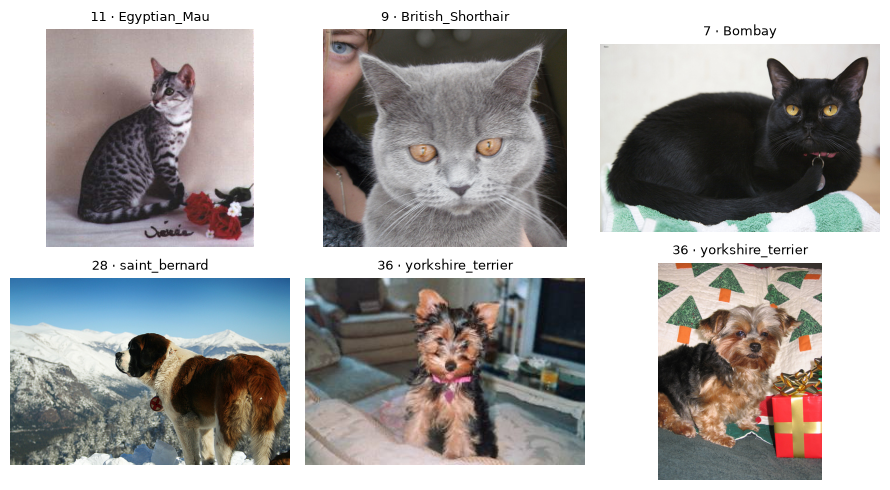

In [5]:
sample = train_df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for ax, row in zip(axes.flat, sample.itertuples()):
    with Image.open(DATA_DIR / row.image_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row.label} · {row.class_name}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

### 학습 전에 사진과 제목을 함께 보는 것이 일반적
- 숫자 표로 이루어진 데이터형태로만 보면 동물의 크기, 사진의 방향, 파일과 라벨의 대응 관계를 일반적으로 파악하기는 어려움

**확인 질문** · 사진 한 장을 골라 동물의 얼굴이 차지하는 면적과 배경을 설명해 보세요.
- 얼굴이 화면에 가장자리에 놓인 사진이라면 임의로 자를 때 중요한 정보인 귀나 눈이 잘릴 수 있는 위험이 있다.
- 반대로 동물이 작게 나온 경우 사진 주변 배경이 입력에서 큰 비중을 차지한다.
- 각 이미지의 특징을 파악하여 전처리 전에 준비한다.

## 05 · 학습과 평가의 입력 변환

학습용 임의 크롭과 좌우 반전을 구성하고, 검증과 테스트에는 사전 학습 가중치에 연결된 평가용 변환을 씁니다.

In [18]:
weights = ResNet18_Weights.IMAGENET1K_V1
eval_transform = weights.transforms()
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=eval_transform.mean, std=eval_transform.std),
])
with Image.open(DATA_DIR / sample.iloc[0]["image_path"]) as image:
    x = eval_transform(image.convert("RGB"))
print("평가용 사진 한 장", tuple(x.shape), x.dtype)
print(eval_transform)

평가용 사진 한 장 (3, 224, 224) torch.float32
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


- 픽셀을 ResNet이 학습했던 입력 형식에 맞추기
- 전처리는 원본 모델 입력 규격으로 바꾸는 과정을 의미하는 데 
- 증강은 정답을 보존할 수 있는 범위에서 사진을 변형해 여러 모습으로 학습하는 방법
- weights는 사용할 ImageNet 사전 학습 가중치 버전을 가리키며
- weights.transforms()는 그 가중치에 맞는 평가 입력 준비법을 가져 온다.

|순서|한 장의 학습 사진에 생기는 변화|
|---|---|
|RandomResizedCrop|원본 면적의 75~100% 범위에서 자를 영역을 시도해 뽑고 224 x 224로 맞춘다. 조금씩 다른 구도의 사진을 보게 만드는 의도|
|RandomHorizontalFlip|사진을 불러 올 때 50% 확률로 좌우를 뒤집겠다. 방향이 바뀌어도 품종 라벨은 유지한다.|
|ToTensor|이 실습의 RGB 픽셀을 0~255 정수에서 0 ~ 1 실수로 변환하고 채널, 높이, 너비, 순서로 정리한다.|
|Normalize|채널별로 (값-평균) / 표준편차를 계산하여 사전 학습 때의 숫자 기준에 맞춘다. 이 뒤의 값은 음수도 될 수 있다.|


**확인 질문** · 사진 한 장의 세 축은 각각 무엇인가요? 같은 검증 사진을 매번 무작위로 자르면 어떤 문제가 생길까요?
- 한 장으 출력값은 (3, 224, 224)입니다. 3은 색 채널이고 다음 두 수는 세로, 가로 픽셀 수 입니다.

## 06 · 사진 한 장을 배치로 묶기

Dataset에서 이미지와 정답을 짝짓고 DataLoader로 여러 장을 한꺼번에 꺼냅니다.

In [7]:
class PetPhotos(Dataset):
    def __init__(self, frame, transform):
        self.rows = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(DATA_DIR / row["image_path"]) as image:
            pixels = self.transform(image.convert("RGB"))
        return pixels, int(row["label"])

train_set = PetPhotos(train_df, train_transform)
val_set = PetPhotos(val_df, eval_transform)
test_set = PetPhotos(test_df, eval_transform)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("사진", tuple(images.shape), "| 정답", tuple(labels.shape), labels.dtype)
print("한 epoch의 학습 배치 수", len(train_loader))

사진 (32, 3, 224, 224) | 정답 (32,) torch.int64
한 epoch의 학습 배치 수 18


- Dataset과 DataLoader의 역할을 사진 한 장으로 이해하기
- PetPhots는 표의 i번째 행을 주면 어떤 사진과 정답을 반환할까?를 정의한다.
- DataLoader는 이 규칙을 반복 적용하여 여러 장을 묶음인 배치로 만든다.
- __getitem__(index) : 지정한 행 파일을 열고 전처리, 그 행이 Abyssinian이면 '사진 텐서, 정수 0' <- 한쌍의 형태로 나온다.
- next(iter(train_loader)) -> 학습 로더에서 첫 배치를 꺼낸다.
- 정답 숫자 하나가 사진 한장에 대응하는 지 확인한다.

**확인 질문** · 첫 배치의 입력 모양과 정답 모양을 적으세요. 마지막 학습 배치에는 사진이 몇 장 들어가나요?
- 이미지는 (32, 3, 224, 224), 정답은 (32,) 이미지와 정답의 첫 축 32가 서로 대응하며, 정답은 정수형 int64 
- 552 = 32 x 17 + 8 이기 때문에 총 18개의 배치, 마지막 장은 8장이다.

## 07 · 사전 학습 모델에서 분류기 교체

ImageNet 가중치를 가져와 기존 값을 고정하고, Oxford 37품종에 맞는 새 선형층을 붙입니다.

In [8]:
model = resnet18(weights=weights)
print("원래 분류기", model.fc)
for parameter in model.parameters():
    parameter.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)
print("교체한 분류기", model.fc)

def trainable_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model.eval()
with torch.no_grad():
    scores = model(images[:2].to(device))
print("사진 2장의 출력", tuple(scores.shape), "| 학습할 값", f"{trainable_count(model):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\hasoo/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:09<00:00, 4.78MB/s]


원래 분류기 Linear(in_features=512, out_features=1000, bias=True)
교체한 분류기 Linear(in_features=512, out_features=37, bias=True)
사진 2장의 출력 (2, 37) | 학습할 값 18,981


- 옮겨 쓰는 것은 백본의 가중치, 새로 배우는 것은 품종별 점수 계산법
<br>> 사전학습은 이전에 과제를 통해 모델의 파라미터를 이미 학습했다는 뜻
<br>> 전이학습은 그 결과를 지금 과제에 가져와 활용하는 과정을 의미

- 사진에서 특징을 계산하는 본체를 백본, 특징으로 최종 점수를 계산하는 층을 분류기 또는 헤드라고 한다.
1. resnet18(weights=weights)는 ImageNet 학습값을 담은 ResNet-18을 불러옴
    - 원래 마지막 층 fc는 사진에서 뽑은 특징 512개를 받아 1,000개 범주의 점수를 나타냄
2. parameter.requires_grad = False : 그 시점의 모델 파라미터에 대해 기울기 계산을 끈다. 기존 가중치를 유지하는 조작을 **동결**이라고 부른다.
3. nn.Linear(model.fc.in_features, len(class_name))로 새 층을 만든다.
    - 기존 층을 동결한 뒤에 만들었기 때문에 개 층의 가중치는 학습 가능하다.
    - 512개의 특징을 어떤 비중으로 결합하여 새로운 품종으로 구별할 지 학습한다.
4. model(images[:2]...)는 두 사진에 대한 점수를 계산하는 순전파를 의미한다.
    - 여기서는 모양을 확인하기 때문에 no_grad()로 기울기 게산 기록을 생략한다.
    - 원시 점수는 이미 알고 있는 **Logit**값이다.

**확인 질문** · 원래 분류기와 새 분류기의 입력·출력 수를 비교하세요. 새로 학습하는 숫자 18,981개는 어떻게 계산하나요?
- 512 -> 1,000개 이던 층이 512 -> 37개로 바뀐다.
- 품종 하나는 512개와 기본값을 더하는 편향 1개를 쓰기 때문에 (512+1) x 37 = 18,891개이다.
- 출력 (2,37)은 두 사진이 각각 37개의 점수를 가졌다는 것을 의미한다.


## 08 · 학습 한 바퀴 정의

사진을 넣고 예측을 계산한 뒤 손실을 구해 파라미터를 갱신하는 순서를 함수로 정의합니다. 실제 호출은 10번입니다.

In [9]:
loss_fn = nn.CrossEntropyLoss()

def train_one_epoch(model, optimizer, tune_last):
    model.eval()  # 고정된 백본의 BatchNorm 통계를 유지합니다.
    model.fc.train()
    if tune_last:
        model.layer4.train()

    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    return total_loss / len(train_set)

- 사진 한 묶음으로 모델을 한 번 바꾸는 순서
- 손실 : 모델이 준 점수가 정답과 얼마나 어긋났는지 수치적으로 나타낸다.
- 기울기 : 가중치를 조금 바꿨을 때 손실이 어느 방향으로 얼마나 달라졌는 지?를 나타내는 값
- 옵티마이저: 이 기울기로 실제 가중치를 조절하는 도구

1. optimizer.zero_grad(...) : 직전 배치에서 남은 기울기를 비운다. 이번 배치에서 구한 영향만을 사용하겠다는 의미
2. logits = model(images) : 사진마다 37개의 원시 점수를 계산
3. loss_fn(logits, labels) : 교차엔트로피가 정답 품종의 상대적 점수를 기준으로 손실을 구한다. 함수 내부에서 필요한 변환을 하므로 로짓 그대로 전달한다.
4. loss.backward() : 손실에서 출발해 각 학습 대상까지 영향을 거꾸로 계산한다. <- 역전파
5. optimizer.step() : 계산한 기울기를 사용하여 실제로 가중치를 갱신한다.

**확인 질문** · 손실을 계산하는 줄, 기울기를 구하는 줄, 가중치가 실제로 바뀌는 줄을 각각 찾으세요.
- BatchNorm은 층을 통과하는 숫자의 분포를 조정하고 훈련 중 평균, 분산 기록을 바꿀 수 있다.
- 고정할 백본에는 평가모드를 사용해 이 기록을 보존한다.
- 갱신할 부분만 훈련모드로 바꾸어 eval()은 층의 작동 방식을, require_grad는 파라미터의 기울기 계산 여부를 제어한다.
- 손실은 4, 기울기는 5, 가중치 변경은 6번째 줄에서 일어난다.

## 09 · 검증과 테스트에 쓸 평가 함수 정의

가중치를 고정한 채 정답과 예측을 모아 손실, 정확도, Macro F1을 계산합니다.

In [10]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    truth, predicted = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        loss = loss_fn(logits, labels.to(device))
        total_loss += loss.item() * len(labels)
        truth.extend(labels.tolist())
        predicted.extend(logits.argmax(dim=1).cpu().tolist())

    return {
        "loss": total_loss / len(truth),
        "accuracy": accuracy_score(truth, predicted),
        "macro_f1": f1_score(truth, predicted, labels=label_ids, average="macro", zero_division=0),
        "truth": truth,
        "predicted": predicted,
    }

- 학습한 값을 바꾸지 않고 채점하기

**확인 질문** · argmax에서 dim=1은 어느 방향인가요? 평가에는 왜 optimizer.step() 호출이 필요 없나요?

## 10 · 1단계 · 분류기만 학습

학습·검증을 4회 반복합니다. 검증 Macro F1이 가장 높은 시점의 모델을 기억합니다.

In [11]:
history = []
best = {"macro_f1": -1.0}

def fit(stage, epochs, optimizer, tune_last=False):
    for epoch in range(1, epochs + 1):
        training_loss = train_one_epoch(model, optimizer, tune_last)
        val = evaluate(model, val_loader)
        history.append({"stage": stage, "epoch": epoch, "train_loss": training_loss,
                        "val_loss": val["loss"], "val_accuracy": val["accuracy"],
                        "val_macro_f1": val["macro_f1"]})
        if val["macro_f1"] > best["macro_f1"]:
            best.update(stage=stage, epoch=epoch, macro_f1=float(val["macro_f1"]),
                        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        print(f'{stage} {epoch}/{epochs} | train loss {training_loss:.3f} | '
              f'val accuracy {val["accuracy"]:.3f} | val Macro F1 {val["macro_f1"]:.3f}')

head_optimizer = torch.optim.AdamW(model.fc.parameters(), lr=0.001)
fit("head", HEAD_EPOCHS, head_optimizer)

head 1/4 | train loss 3.233 | val accuracy 0.424 | val Macro F1 0.344
head 2/4 | train loss 2.039 | val accuracy 0.777 | val Macro F1 0.770
head 3/4 | train loss 1.341 | val accuracy 0.826 | val Macro F1 0.815
head 4/4 | train loss 0.960 | val accuracy 0.864 | val Macro F1 0.862


**확인 질문** · 어느 epoch에서 최고 검증 점수가 나왔나요? 학습 손실과 함께 기록하세요.

## 11 · 2단계 · 마지막 블록까지 미세조정

1단계 최고 모델에서 출발해 layer4와 분류기만 2회 더 학습합니다.

In [12]:
model.load_state_dict(best["state"])
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
tune_optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 0.00001},
    {"params": model.fc.parameters(), "lr": 0.0003},
])
print("부분 미세조정에서 학습할 값", f"{trainable_count(model):,}")
fit("tune", TUNE_EPOCHS, tune_optimizer, tune_last=True)

부분 미세조정에서 학습할 값 8,412,709
tune 1/2 | train loss 1.062 | val accuracy 0.832 | val Macro F1 0.822
tune 2/2 | train loss 0.841 | val accuracy 0.826 | val Macro F1 0.815


**확인 질문** · 학습 가능한 파라미터 수가 얼마나 늘었나요? 어느 쪽의 학습률이 더 작나요?

## 12 · 두 단계 비교와 최종 선택

단계별 최고 검증 결과를 표로 비교하고, 여섯 번의 학습 동안 손실과 검증 지표가 어떻게 달라졌는지 봅니다.

,stage,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
3,head,4,0.9598,0.9823,0.8641,0.8615
4,tune,1,1.0624,1.0079,0.8315,0.8220


최종 선택 head | 단계 내 epoch 4


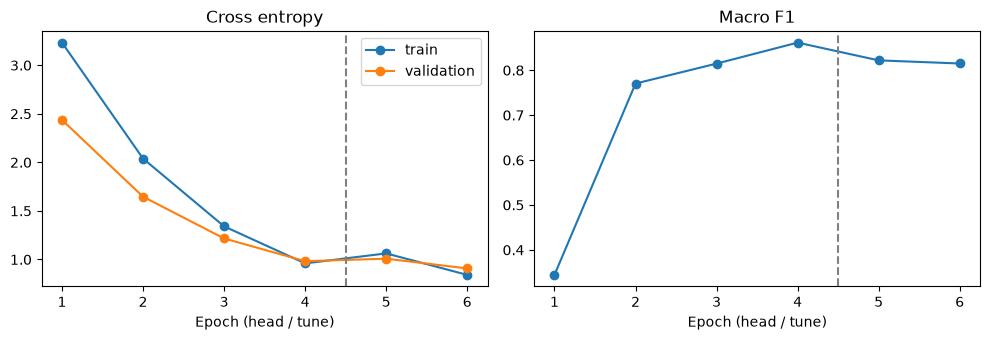

In [13]:
results = pd.DataFrame(history)
best_rows = results.groupby("stage", sort=False)["val_macro_f1"].idxmax()
display(results.loc[best_rows].round(4))
print("최종 선택", best["stage"], "| 단계 내 epoch", best["epoch"])

steps = np.arange(1, len(results) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(steps, results["train_loss"], "o-", label="train")
axes[0].plot(steps, results["val_loss"], "o-", label="validation")
axes[0].set_title("Cross entropy")
axes[0].legend()
axes[1].plot(steps, results["val_macro_f1"], "o-", label="validation")
axes[1].set_title("Macro F1")
for ax in axes:
    ax.axvline(HEAD_EPOCHS + 0.5, color="gray", linestyle="--")
    ax.set(xlabel="Epoch (head / tune)", xticks=steps)
fig.tight_layout()
plt.show()

**확인 질문** · 선택한 단계와 epoch를 적고 상대 단계와의 검증 Macro F1 차이를 계산하세요.

## 13 · 선택한 모델 저장·복원

최고 가중치, 품종 이름 순서, 선택한 단계를 저장했다가 같은 모델 구조에 복원합니다.

In [14]:
checkpoint_path = Path("outputs/oxford_resnet18_best.pt")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
torch.save({**best, "classes": class_names}, checkpoint_path)
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
final_model = resnet18(weights=None)
final_model.fc = nn.Linear(final_model.fc.in_features, len(saved["classes"]))
final_model.load_state_dict(saved["state"])
final_model = final_model.to(device).eval()
print("복원된 모델", saved["stage"], "epoch", saved["epoch"], "|", checkpoint_path)

복원된 모델 head epoch 4 | outputs\oxford_resnet18_best.pt


**확인 질문** · 저장된 단계와 epoch는 12번에서 고른 결과와 같은가요? 품종명 순서가 필요한 이유는 무엇인가요?

## 14 · 독립 테스트 성능 측정

최종 선택을 끝낸 모델로 테스트 전체를 평가하고, 자주 놓친 품종의 지표를 확인합니다.

In [15]:
test = evaluate(final_model, test_loader)
truth, predicted = test["truth"], test["predicted"]
assert truth == test_df["label"].tolist()
print(f'Test {len(truth)}장 | Accuracy {test["accuracy"]:.4f} | Macro F1 {test["macro_f1"]:.4f}')
report = classification_report(truth, predicted, labels=label_ids, target_names=class_names,
                               output_dict=True, zero_division=0)
per_breed = pd.DataFrame(report).T.loc[class_names]
display(per_breed.sort_values("recall").head(5).round(3))

Test 3669장 | Accuracy 0.8231 | Macro F1 0.8213


,precision,recall,f1-score,support
British_Shorthair,0.671,0.470,0.553,100.0
Egyptian_Mau,0.907,0.505,0.649,97.0
american_pit_bull_terrier,0.600,0.510,0.551,100.0
staffordshire_bull_terrier,0.590,0.551,0.570,89.0
Maine_Coon,0.679,0.570,0.620,100.0


**확인 질문** · 표에서 재현율이 가장 낮은 품종의 실제 사진 수와 맞힌 비율을 읽으세요.

## 15 · 틀린 품종 쌍과 원본 사진 분석

혼동 행렬의 행은 실제 품종, 열은 예측 품종입니다. 오분류 횟수가 많은 쌍과 틀린 사진을 확인합니다.

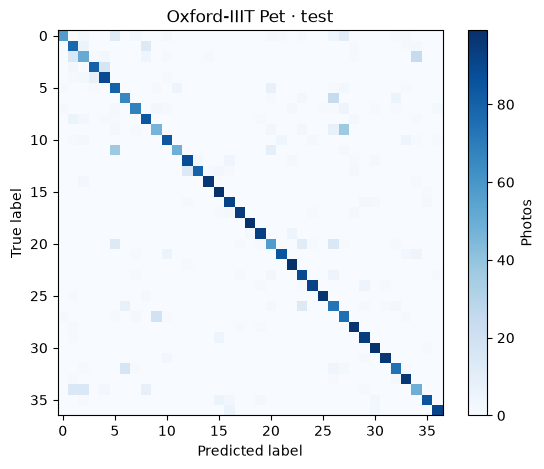

,True breed,Predicted breed,Photos
0,British_Shorthair,Russian_Blue,37
1,Egyptian_Mau,Bengal,37
2,american_pit_bull_terrier,staffordshire_bull_terrier,24
3,Birman,Ragdoll,24
4,Russian_Blue,British_Shorthair,19


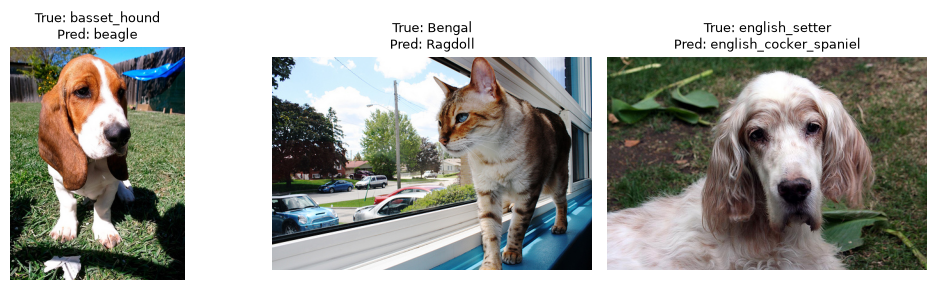

In [16]:
cm = confusion_matrix(truth, predicted, labels=label_ids)
fig, ax = plt.subplots(figsize=(6.5, 5))
heat = ax.imshow(cm, cmap="Blues")
ax.set(xlabel="Predicted label", ylabel="True label", title="Oxford-IIIT Pet · test")
fig.colorbar(heat, ax=ax, label="Photos")
plt.show()

pairs = [(class_names[i], class_names[j], cm[i, j])
         for i, j in zip(*np.nonzero(cm)) if i != j]
pairs.sort(key=lambda item: item[2], reverse=True)
display(pd.DataFrame(pairs[:5], columns=["True breed", "Predicted breed", "Photos"]))

wrong = np.flatnonzero(np.array(truth) != np.array(predicted))
if len(wrong):
    chosen = np.random.default_rng(SEED).choice(wrong, min(3, len(wrong)), replace=False)
    fig, axes = plt.subplots(1, len(chosen), figsize=(3.4 * len(chosen), 3), squeeze=False)
    for ax, i in zip(axes.flat, chosen):
        with Image.open(DATA_DIR / test_df.iloc[i]["image_path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"True: {class_names[truth[i]]}\nPred: {class_names[predicted[i]]}", fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("오분류된 사진이 없습니다.")

**확인 질문** · 가장 많이 혼동한 방향을 실제 품종 → 예측 품종으로 기록하세요. 사진에서 관찰한 점 한 가지를 적으세요.

## 16 · 사진 한 장으로 직접 예측

복원한 모델에 사진 한 장을 넣고 상위 세 후보를 확인합니다. 기본값으로 바로 실행할 수 있고, photo_path를 바꾸면 다른 사진도 예측할 수 있습니다.

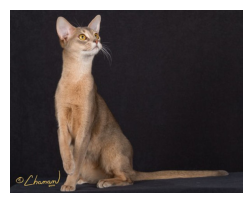

,rank,breed,score
0,1,Abyssinian,0.2163
1,2,Russian_Blue,0.1909
2,3,Sphynx,0.0984


In [17]:
# 기본값은 첨부본의 첫 테스트 사진입니다. 내 사진을 보려면 이 경로만 바꾸세요.
photo_path = DATA_DIR / test_df.iloc[0]["image_path"]
with Image.open(photo_path) as image:
    photo = image.convert("RGB")
    inputs = eval_transform(photo).unsqueeze(0).to(device)

with torch.inference_mode():
    probs = final_model(inputs).softmax(dim=1)
    top_scores, top_labels = probs[0].topk(3)

plt.figure(figsize=(3, 3))
plt.imshow(photo)
plt.axis("off")
plt.show()
display(pd.DataFrame({
    "rank": [1, 2, 3],
    "breed": [saved["classes"][j] for j in top_labels.tolist()],
    "score": top_scores.tolist(),
}).round(4))

**확인 질문** · 상위 두 품종과 점수 차이를 적으세요. 첫 후보의 점수가 0.5보다 낮아도 1위가 될 수 있는 이유는 무엇인가요?

## 실습 결과 기록

| 기록 항목 | 내 실행 결과 |
|---|---|
| 장치와 학습·검증·테스트 장수 | |
| 분류기만 학습한 단계의 최고 검증 Macro F1 | |
| 마지막 블록까지 학습한 단계의 최고 검증 Macro F1 | |
| 선택한 단계와 epoch, 그 근거 | |
| 테스트 정확도와 Macro F1 | |
| 관찰한 오분류 한 건과 원인 가설 | |